In [1]:
import os
from pathlib import Path

# Walk up until we find the repo root (identified by CLAUDE.md)
_here = Path(os.getcwd())
while not (_here / "CLAUDE.md").exists() and _here != _here.parent:
    _here = _here.parent
os.chdir(_here)
del _here

import duckdb
import joblib
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.patches as mpatches
import statsmodels.formula.api as smf
from scipy.stats import sem

%matplotlib inline

Path("results").mkdir(exist_ok=True)
Path("results/plots").mkdir(exist_ok=True)

DARK  = "#2c3e50"; MID  = "#7f8c8d"; GOLD  = "#e8b84b"
RED   = "#e74c3c"; BLUE = "#3498db"; GREEN = "#27ae60"; BG = "#f8f8f8"

MIN_SWINGS = 200
COMMIT_MS  = 150

# Empirical baseline columns: expected plate location from KNN on commit-time state
EMP_DEV_X   = f"pc{COMMIT_MS}_emp_dev_x"    # actual - KNN-expected plate_x
EMP_DEV_Z   = f"pc{COMMIT_MS}_emp_dev_z"    # actual - KNN-expected plate_z
EMP_X_PROJ  = f"pc{COMMIT_MS}_emp_x_proj"   # KNN-expected plate_x
EMP_Z_PROJ  = f"pc{COMMIT_MS}_emp_z_proj"   # KNN-expected plate_z

# Gravity-corrected linear deviation (spin-induced only, gravity stripped out)
LIN_DEV_X   = f"pc{COMMIT_MS}_dev_x"
LIN_DEV_Z   = f"pc{COMMIT_MS}_dev_z"

# Primary treatment columns used throughout (empirical baseline)
DEV_X = EMP_DEV_X
DEV_Z = EMP_DEV_Z

AXIS_COLS  = ("vert_attack_angle_dev", "horz_attack_angle_dev", "swing_path_tilt_dev")
AXIS_LBL   = {"vert_attack_angle_dev": "VAA",
              "horz_attack_angle_dev": "HAA",
              "swing_path_tilt_dev":   "Tilt"}


def _spine_clean(ax):
    for sp in ["top", "right"]:
        ax.spines[sp].set_visible(False)
    ax.spines["left"].set_color(MID)
    ax.spines["bottom"].set_color(MID)


def _eb_shrink(means, ns, within_var, between_var, grand):
    w = ns / (ns + within_var / between_var)
    return w * means + (1 - w) * grand

Path("results/plots/leaderboards").mkdir(parents=True, exist_ok=True)
Path("results/plots/validation").mkdir(parents=True, exist_ok=True)
Path("results/plots/diagnostics").mkdir(parents=True, exist_ok=True)
Path("results/plots/case_studies").mkdir(parents=True, exist_ok=True)
Path("results/plots/applications").mkdir(parents=True, exist_ok=True)


In [2]:
_cache = {}


def _load(key, fn):
    if key not in _cache:
        _cache[key] = fn()
    return _cache[key]


_PC_COLS = ", ".join([
    "game_pk", "at_bat_number", "pitch_number", "game_year",
    # Empirical baseline (KNN commit-time expected plate location)
    EMP_DEV_X, EMP_DEV_Z, EMP_X_PROJ, EMP_Z_PROJ,
    # Gravity-corrected linear deviation (spin-induced only)
    LIN_DEV_X, LIN_DEV_Z,
    "ball_bat_miss", "is_whiff",
    "is_contact", "is_bip", "is_single", "is_double", "is_triple", "is_home_run",
    "is_swing", "bat_speed", "count_group", "balls", "strikes", "vert_attack_angle",
    "pitcher_full_name", "pitch_type", "pfx_x", "pfx_z",
    f"pc{COMMIT_MS}_R_x", f"pc{COMMIT_MS}_R_y", f"pc{COMMIT_MS}_R_z",
    f"pc{COMMIT_MS}_V_x", f"pc{COMMIT_MS}_V_y", f"pc{COMMIT_MS}_V_z",
    f"pc{COMMIT_MS}_A_x", f"pc{COMMIT_MS}_A_y", f"pc{COMMIT_MS}_A_z",
    f"pc{COMMIT_MS}_t_plate",
])

_SXRV_COLS = ", ".join([
    "game_pk", "at_bat_number", "pitch_number", "pitcher_id", "pitcher_full_name",
    "pfx_x", "pfx_z", "release_speed", "release_extension", "arm_angle",
    "ivb_transverse", "hb_transverse", "pitcher_throws", "stuff_grade", "xrv_vs_count", "xrv",
])


def xrv():  return _load("xrv",  lambda: duckdb.sql("SELECT * FROM read_parquet('results/xrv_causal.parquet')").df())
def pc():   return _load("pc",   lambda: duckdb.sql(f"SELECT {_PC_COLS} FROM read_parquet('data/swings_precommit.parquet')").df())
def sxrv(): return _load("sxrv", lambda: duckdb.sql(f"SELECT {_SXRV_COLS} FROM read_parquet('results/swing_xrv.parquet')").df())


def merged():
    if "merged" in _cache:
        return _cache["merged"]
    pc_cols = ["game_pk", "at_bat_number", "pitch_number", "game_year",
               EMP_DEV_X, EMP_DEV_Z, LIN_DEV_X, LIN_DEV_Z, "ball_bat_miss", "is_whiff"]
    sx_cols = ["game_pk", "at_bat_number", "pitch_number", "pitcher_full_name",
               "pfx_x", "pfx_z", "release_speed", "release_extension", "arm_angle",
               "ivb_transverse", "hb_transverse", "pitcher_throws",
               "stuff_grade", "xrv_vs_count", "xrv"]
    K = ["game_pk", "at_bat_number", "pitch_number"]
    df = (xrv()
          .merge(pc()[pc_cols], on=K, how="left")
          .merge(sxrv()[sx_cols], on=K, how="left"))
    _cache["merged"] = df
    return df



_SXRV_EXT_COLS = ", ".join([
    "game_pk", "at_bat_number", "pitch_number", "pitcher_id",
    "batter_id", "batter_full_name", "game_year",
    "pitch_type", "pitch_group", "plate_x", "plate_z",
    "xwoba", "is_whiff", "is_bip", "stuff_grade", "xrv",
])

def sxrv_extended():
    return _load("sxrv_ext", lambda: duckdb.sql(
        f"SELECT {_SXRV_EXT_COLS} FROM read_parquet('results/swing_xrv.parquet')"
    ).df())

# Incremental Validity

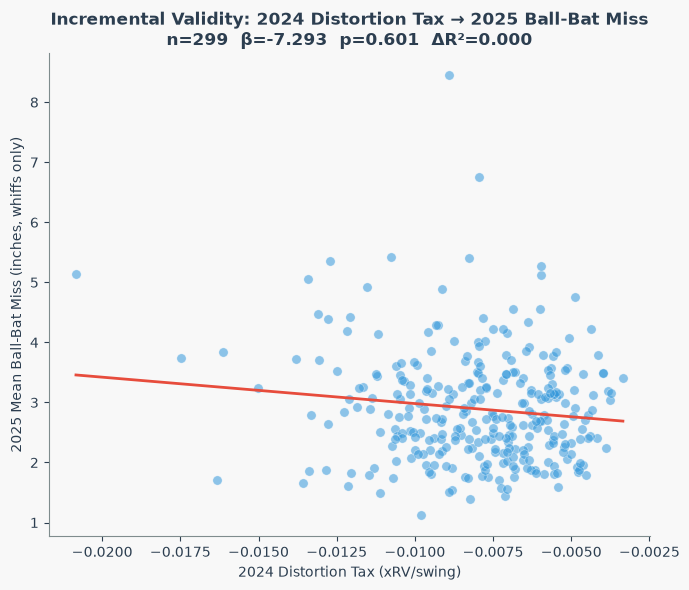

Saved results/plots/validation/distortion_tax_incremental_validity.png


In [6]:
df = merged()
MIN_WHIFFS = 50

dist_agg = (df[df["distortion_tax"].notna()]
            .groupby(["pitcher_id", "pitcher_full_name", "game_year"])
            .agg(n=("distortion_tax", "size"),
                 distortion_tax=("distortion_tax", "mean"),
                 xrv=("xrv", "mean"))
            .reset_index()
            .query(f"n >= {MIN_SWINGS}"))

bbm_agg = (df[(df["is_whiff"] == 1) & df["ball_bat_miss"].notna()]
           .groupby(["pitcher_id", "game_year"])
           .agg(n_whiffs=("ball_bat_miss", "size"), ball_bat_miss=("ball_bat_miss", "mean"))
           .reset_index()
           .query(f"n_whiffs >= {MIN_WHIFFS}"))

season_agg = dist_agg.merge(bbm_agg, on=["pitcher_id", "game_year"], how="left")

validity_rows = []
for yr_a, yr_b in [(2023, 2024), (2024, 2025)]:
    ya  = season_agg[season_agg["game_year"] == yr_a]
    yb  = (season_agg[season_agg["game_year"] == yr_b][["pitcher_id", "ball_bat_miss"]]
           .rename(columns={"ball_bat_miss": "next_bbm"}))
    pair = (ya.merge(yb, on="pitcher_id", how="inner")
              .dropna(subset=["ball_bat_miss", "next_bbm", "distortion_tax"]))
    if len(pair) < 20:
        continue
    m0 = smf.ols("next_bbm ~ ball_bat_miss", pair).fit()
    m1 = smf.ols("next_bbm ~ ball_bat_miss + distortion_tax", pair).fit()
    validity_rows.append({
        "transition": f"{yr_a}->{yr_b}", "n": len(pair),
        "baseline_r2": m0.rsquared, "full_r2": m1.rsquared,
        "delta_r2": m1.rsquared - m0.rsquared,
        "coef":   m1.params.get("distortion_tax", np.nan),
        "pvalue": m1.pvalues.get("distortion_tax", np.nan),
    })

csv = Path("results/incremental_validity.csv")
if not csv.exists() and validity_rows:
    pd.DataFrame(validity_rows).to_csv(csv, index=False)

best = max(validity_rows, key=lambda r: r["n"])
yr_a, yr_b = [int(x) for x in best["transition"].split("->")]
ya   = season_agg[season_agg["game_year"] == yr_a]
yb   = (season_agg[season_agg["game_year"] == yr_b][["pitcher_id", "ball_bat_miss"]]
        .rename(columns={"ball_bat_miss": "next_bbm"}))
pair = (ya.merge(yb, on="pitcher_id", how="inner")
          .dropna(subset=["distortion_tax", "ball_bat_miss", "next_bbm"]))

fig, ax = plt.subplots(figsize=(7, 6), facecolor=BG)
ax.set_facecolor(BG)
ax.scatter(pair["distortion_tax"], pair["next_bbm"],
           alpha=0.55, color=BLUE, edgecolors="white", lw=0.4, s=45)
m_plot = smf.ols("next_bbm ~ distortion_tax", pair).fit()
xs = np.linspace(pair["distortion_tax"].min(), pair["distortion_tax"].max(), 200)
ax.plot(xs, m_plot.params["Intercept"] + m_plot.params["distortion_tax"] * xs,
        color=RED, lw=2)
ax.set_xlabel(f"{yr_a} Distortion Tax (xRV/swing)", color=DARK)
ax.set_ylabel(f"{yr_b} Mean Ball-Bat Miss (inches, whiffs only)", color=DARK)
ax.set_title(
    f"Incremental Validity: {yr_a} Distortion Tax \u2192 {yr_b} Ball-Bat Miss\n"
    f"n={best['n']}  \u03b2={best['coef']:.3f}  p={best['pvalue']:.3f}  "
    f"\u0394R\u00b2={best['delta_r2']:.3f}",
    color=DARK, fontweight="bold")
_spine_clean(ax); ax.tick_params(colors=DARK)
fig.tight_layout()
out = "results/plots/validation/distortion_tax_incremental_validity.png"
fig.savefig(out, dpi=150, bbox_inches="tight")
plt.show()
print(f"Saved {out}")


# Outcome Rates

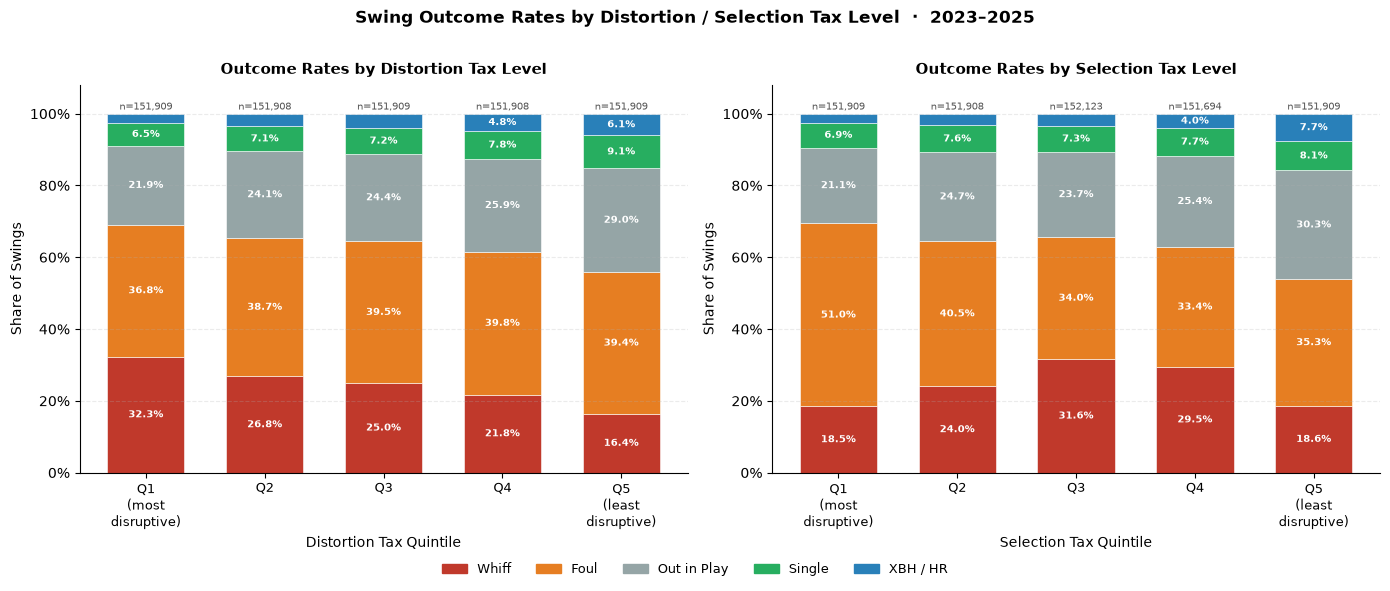

Saved results/plots/validation/outcome_rates.png


In [7]:
sw = (pc()[["game_pk", "at_bat_number", "pitch_number",
            "is_whiff", "is_contact", "is_bip",
            "is_single", "is_double", "is_triple", "is_home_run"]]
      .drop_duplicates(subset=["game_pk", "at_bat_number", "pitch_number"]))
df = (xrv()
      .merge(sw, on=["game_pk", "at_bat_number", "pitch_number"], how="inner")
      .dropna(subset=["distortion_tax", "selection_tax"]))

df["is_foul"]        = (df["is_contact"] == 1) & (df["is_bip"] == 0)
df["is_out_in_play"] = ((df["is_bip"] == 1) & (df["is_home_run"] == 0) &
                        (df["is_triple"] == 0) & (df["is_double"] == 0) &
                        (df["is_single"] == 0))
df["is_xbh"]  = ((df["is_bip"] == 1) & ((df["is_double"] == 1) |
                 (df["is_triple"] == 1) | (df["is_home_run"] == 1)))

OUTCOMES = [("Whiff",       "is_whiff",       "#c0392b"),
            ("Foul",        "is_foul",         "#e67e22"),
            ("Out in Play", "is_out_in_play",  "#95a5a6"),
            ("Single",      "is_single",       "#27ae60"),
            ("XBH / HR",    "is_xbh",          "#2980b9")]
N_BINS = 5
BIN_LABS = ["Q1\n(most\ndisruptive)", "Q2", "Q3", "Q4", "Q5\n(least\ndisruptive)"]

fig, axes = plt.subplots(1, 2, figsize=(14, 5.5))
fig.patch.set_facecolor("white")

for ax, metric, xlabel, title in [
    (axes[0], "distortion_tax", "Distortion Tax Quintile",
     "Outcome Rates by Distortion Tax Level"),
    (axes[1], "selection_tax",  "Selection Tax Quintile",
     "Outcome Rates by Selection Tax Level"),
]:
    df["_bin"] = pd.qcut(df[metric], q=N_BINS, labels=False, duplicates="drop")
    bottoms = np.zeros(N_BINS)
    for lbl, col, color in OUTCOMES:
        rates = df.groupby("_bin")[col].mean().reindex(range(N_BINS)).fillna(0).values
        ax.bar(range(N_BINS), rates, 0.65, bottom=bottoms,
               color=color, label=lbl, edgecolor="white", linewidth=0.4)
        for i, (r, b) in enumerate(zip(rates, bottoms)):
            if r > 0.04:
                ax.text(i, b + r / 2, f"{r:.1%}", ha="center", va="center",
                        fontsize=7.5, color="white", fontweight="bold")
        bottoms += rates
    for i in range(N_BINS):
        n = (df["_bin"] == i).sum()
        ax.text(i, bottoms[i] + 0.005, f"n={n:,}", ha="center", va="bottom",
                fontsize=7, color="#555")
    ax.set_xticks(range(N_BINS)); ax.set_xticklabels(BIN_LABS, fontsize=9)
    ax.set_xlabel(xlabel, fontsize=10)
    ax.set_ylabel("Share of Swings", fontsize=10)
    ax.set_title(title, fontsize=11, fontweight="bold", pad=8)
    ax.set_ylim(0, 1.08)
    ax.yaxis.set_major_formatter(plt.FuncFormatter(lambda y, _: f"{y:.0%}"))
    ax.spines[["top", "right"]].set_visible(False)
    ax.grid(axis="y", alpha=0.25, linestyle="--")

handles = [mpatches.Patch(color=c, label=l) for l, _, c in OUTCOMES]
fig.legend(handles=handles, loc="lower center", ncol=5,
           fontsize=9, frameon=False, bbox_to_anchor=(0.5, -0.04))
fig.suptitle("Swing Outcome Rates by Distortion / Selection Tax Level  \u00b7  2023\u20132025",
             fontsize=12, fontweight="bold", y=1.01)
fig.tight_layout()
out = "results/plots/validation/outcome_rates.png"
fig.savefig(out, dpi=150, bbox_inches="tight", facecolor="white")
plt.show()
print(f"Saved {out}")


# xwOBA vs Tax

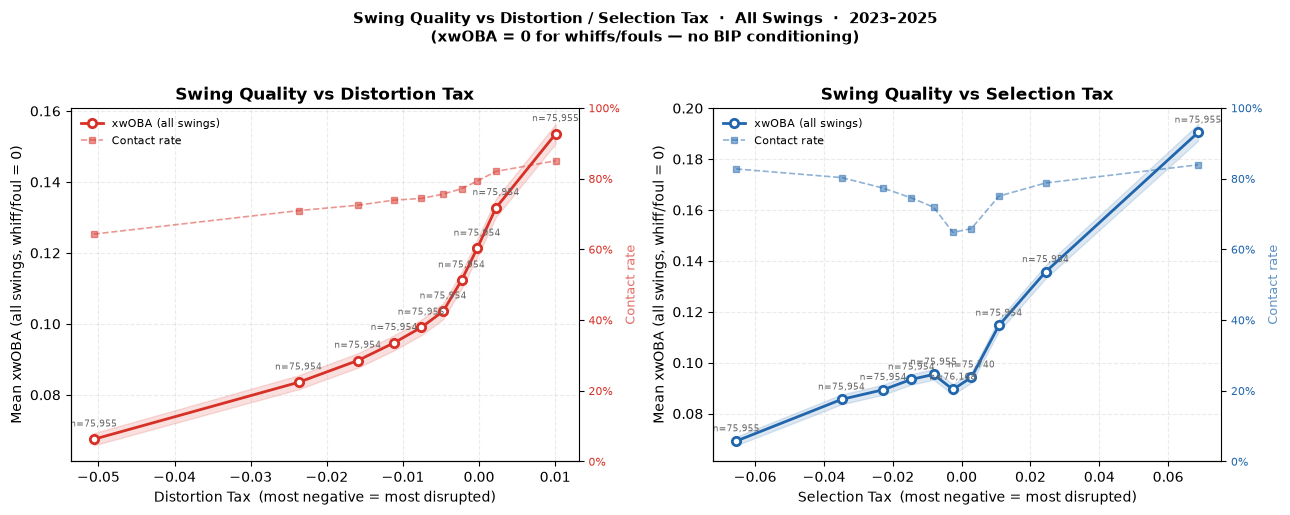

Saved results/plots/validation/xwoba_relationship.png


In [8]:
sw = (pc()[["game_pk", "at_bat_number", "pitch_number",
            "is_contact", "is_bip", "is_single", "is_double",
            "is_triple", "is_home_run"]]
      .drop_duplicates(subset=["game_pk", "at_bat_number", "pitch_number"]))
df = (xrv()
      .merge(sw, on=["game_pk", "at_bat_number", "pitch_number"], how="inner")
      .dropna(subset=["distortion_tax", "selection_tax"]))

df["is_out_in_play"] = ((df["is_bip"] == 1) & (df["is_home_run"] == 0) &
                        (df["is_triple"] == 0) & (df["is_double"] == 0) &
                        (df["is_single"] == 0))
lw = pd.read_csv("results/linear_weights.csv").set_index("outcome_type")["lw"]
bip = df["is_bip"] == 1
xw  = pd.Series(0.0, index=df.index)
xw.loc[bip & (df["is_home_run"] == 1)] = lw["home_run"]
xw.loc[bip & (df["is_triple"] == 1) & ~(df["is_home_run"] == 1)] = lw["triple"]
xw.loc[bip & (df["is_double"] == 1) & ~(df["is_triple"] == 1) & ~(df["is_home_run"] == 1)] = lw["double"]
xw.loc[bip & (df["is_single"] == 1) & ~(df["is_double"] == 1) & ~(df["is_triple"] == 1) & ~(df["is_home_run"] == 1)] = lw["single"]
xw.loc[df["is_out_in_play"]] = lw["out_in_play"]
df["xwoba_all"] = xw

fig, axes = plt.subplots(1, 2, figsize=(13, 5)); fig.patch.set_facecolor("white")
for ax, metric, label, color in [
    (axes[0], "distortion_tax", "Distortion Tax", "#d73027"),
    (axes[1], "selection_tax",  "Selection Tax",  "#2166ac"),
]:
    df["_bin"] = pd.qcut(df[metric], q=10, labels=False, duplicates="drop")
    s = (df.groupby("_bin")
         .agg(mid=(metric, "mean"),
              mean_xw=("xwoba_all", "mean"),
              se_xw=("xwoba_all", lambda x: sem(x, nan_policy="omit")),
              contact=("is_contact", "mean"),
              n=("xwoba_all", "count"))
         .reset_index())
    ax.fill_between(s["mid"], s["mean_xw"] - 1.96*s["se_xw"],
                    s["mean_xw"] + 1.96*s["se_xw"], alpha=0.15, color=color)
    ax.plot(s["mid"], s["mean_xw"], "o-", color=color, lw=2, ms=6,
            mfc="white", mew=2, label="xwOBA (all swings)")
    ax2r = ax.twinx()
    ax2r.plot(s["mid"], s["contact"], "s--", color=color, lw=1.2, ms=4,
              alpha=0.5, label="Contact rate")
    ax2r.set_ylabel("Contact rate", fontsize=9, color=color, alpha=0.7)
    ax2r.tick_params(axis="y", labelcolor=color, labelsize=8)
    ax2r.set_ylim(0, 1)
    ax2r.yaxis.set_major_formatter(plt.FuncFormatter(lambda y, _: f"{y:.0%}"))
    for _, r in s.iterrows():
        ax.text(r["mid"], r["mean_xw"] + 0.003, f"n={int(r['n']):,}",
                ha="center", va="bottom", fontsize=6.5, color="#666")
    ax.set_xlabel(f"{label}  (most negative = most disrupted)", fontsize=10)
    ax.set_ylabel("Mean xwOBA (all swings, whiff/foul = 0)", fontsize=10)
    ax.set_title(f"Swing Quality vs {label}", fontsize=12, fontweight="bold")
    ax.spines[["top", "right"]].set_visible(False)
    ax.grid(True, alpha=0.25, linestyle="--")
    l1, lb1 = ax.get_legend_handles_labels(); l2, lb2 = ax2r.get_legend_handles_labels()
    ax.legend(l1+l2, lb1+lb2, fontsize=8, frameon=False, loc="upper left")
fig.suptitle("Swing Quality vs Distortion / Selection Tax  \u00b7  All Swings  \u00b7  2023\u20132025\n"
             "(xwOBA = 0 for whiffs/fouls \u2014 no BIP conditioning)",
             fontsize=11, fontweight="bold", y=1.02)
fig.tight_layout()
out = "results/plots/validation/xwoba_relationship.png"
fig.savefig(out, dpi=150, bbox_inches="tight", facecolor="white")
plt.show()
print(f"Saved {out}")


# Reliability

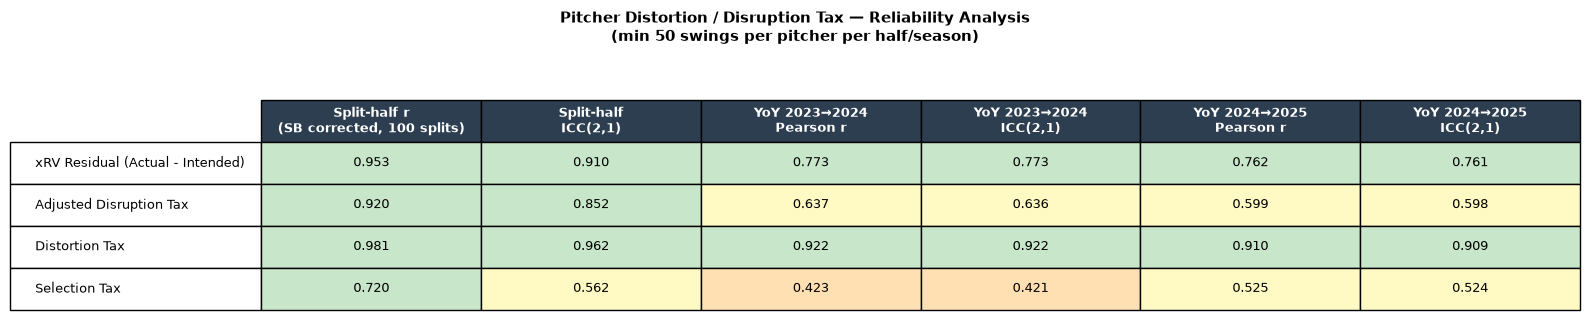

Saved results/plots/validation/reliability.png


In [9]:
METRICS = ["disruption_tax", "adjusted_disruption_tax", "distortion_tax", "selection_tax"]
METRIC_LABELS = {
    "disruption_tax":          "xRV Residual (Actual - Intended)",
    "adjusted_disruption_tax": "Adjusted Disruption Tax",
    "distortion_tax":          "Distortion Tax",
    "selection_tax":           "Selection Tax",
}
N_SPLITS = 100; SEED = 42; MIN_SH = 50

sw = (pc()[["game_pk", "at_bat_number", "pitch_number", "game_year"]]
      .drop_duplicates(subset=["game_pk", "at_bat_number", "pitch_number"]))
df = (xrv()
      .merge(sw, on=["game_pk", "at_bat_number", "pitch_number"], how="left")
      .dropna(subset=METRICS + ["game_year", "pitcher_id"]))


def _icc21(y):
    y = np.asarray(y, float); n, k = y.shape
    if n < 3 or k < 2: return np.nan
    gm = y.mean(); rm = y.mean(1); cm = y.mean(0)
    ssb = k * ((rm-gm)**2).sum(); ssr = n * ((cm-gm)**2).sum()
    sse = ((y-gm)**2).sum() - ssb - ssr
    msb = ssb/(n-1); msr = ssr/(k-1); mse = sse/((n-1)*(k-1))
    d = msb + (k-1)*mse + k/n*(msr-mse)
    return np.nan if d <= 0 else float((msb-mse)/d)


def split_half(metric):
    rng   = np.random.default_rng(SEED)
    valid = df.groupby("pitcher_id")[metric].transform("size") >= MIN_SH * 2
    pool  = df.loc[valid, ["pitcher_id", metric]].copy()
    pids  = pool["pitcher_id"].unique()
    if len(pids) < 10: return np.nan, np.nan
    rs, iccs = [], []
    for _ in range(N_SPLITS):
        h1, h2 = [], []
        for pid in pids:
            g = pool.loc[pool["pitcher_id"] == pid, metric].values
            idx = rng.permutation(len(g)); half = len(g) // 2
            h1.append(g[idx[:half]].mean()); h2.append(g[idx[half:]].mean())
        r = np.corrcoef(h1, h2)[0, 1]
        rs.append(2*r/(1+r))
        iccs.append(_icc21(np.column_stack([h1, h2])))
    return float(np.mean(rs)), float(np.nanmean(iccs))


def yoy(yr_a, yr_b, metric):
    def means(yr):
        g = df[df["game_year"] == yr].groupby("pitcher_id")[metric]
        a = g.agg(mean="mean", n="size"); return a[a["n"] >= MIN_SH]["mean"]
    a = means(yr_a); b = means(yr_b); both = a.index.intersection(b.index)
    if len(both) < 10: return np.nan, np.nan
    return (float(a.loc[both].corr(b.loc[both])),
            float(_icc21(np.column_stack([a.loc[both].values, b.loc[both].values]))))


rows = []
for m in METRICS:
    sh_r, sh_icc   = split_half(m)
    r2324, icc2324 = yoy(2023, 2024, m)
    r2425, icc2425 = yoy(2024, 2025, m)
    rows.append({"metric": m, "sh_r": sh_r, "sh_icc": sh_icc,
                 "yoy_23_24_r": r2324, "yoy_23_24_icc": icc2324,
                 "yoy_24_25_r": r2425, "yoy_24_25_icc": icc2425})

tbl = pd.DataFrame(rows).set_index("metric")
tbl.to_csv("results/reliability.csv")


def _fmt(r): return "\u2014" if np.isnan(r) else f"{r:.3f}"
def _col(r):
    if np.isnan(r): return "#f0f0f0"
    if r >= 0.7:    return "#c8e6c9"
    if r >= 0.5:    return "#fff9c4"
    if r >= 0.3:    return "#ffe0b2"
    return "#ffcdd2"


COL_HDR = ["Split-half r\n(SB corrected, 100 splits)", "Split-half\nICC(2,1)",
           "YoY 2023\u21922024\nPearson r",             "YoY 2023\u21922024\nICC(2,1)",
           "YoY 2024\u21922025\nPearson r",             "YoY 2024\u21922025\nICC(2,1)"]
cell_text, cell_color = [], []
for _, row in tbl.iterrows():
    vals = [row["sh_r"], row["sh_icc"], row["yoy_23_24_r"],
            row["yoy_23_24_icc"], row["yoy_24_25_r"], row["yoy_24_25_icc"]]
    cell_text.append([_fmt(v) for v in vals])
    cell_color.append([_col(v) for v in vals])

fig, ax = plt.subplots(figsize=(16, 3.2)); ax.axis("off")
fig.suptitle(f"Pitcher Distortion / Disruption Tax \u2014 Reliability Analysis\n"
             f"(min {MIN_SH} swings per pitcher per half/season)",
             fontsize=11, fontweight="bold", y=1.03)
t = ax.table(cellText=cell_text, cellColours=cell_color,
             rowLabels=[METRIC_LABELS[m] for m in tbl.index],
             colLabels=COL_HDR, cellLoc="center", loc="center")
t.auto_set_font_size(False); t.set_fontsize(9); t.scale(1, 2.6)
for j in range(len(COL_HDR)):
    t[(0, j)].set_facecolor("#2c3e50"); t[(0, j)].get_text().set_color("white")
    t[(0, j)].get_text().set_fontweight("bold")
fig.tight_layout()
out = "results/plots/validation/reliability.png"
fig.savefig(out, dpi=150, bbox_inches="tight")
plt.show()
print(f"Saved {out}")


In [ ]:
csv = Path("results/convergent_validity.csv")
if not csv.exists():
    dev_col = duckdb.sql("""
        SELECT game_pk, at_bat_number, pitch_number, pc150_dev_total
        FROM read_parquet('data/swings_precommit.parquet')
    """).df()

    BREAKING_TYPES = ["SL", "CU", "ST", "KC", "SV", "CS"]
    cv = (xrv()
          .query("pitch_type in @BREAKING_TYPES")
          .merge(dev_col, on=["game_pk", "at_bat_number", "pitch_number"], how="left")
          .dropna(subset=["distortion_tax", "pc150_dev_total"])
          .groupby("pitcher_id")
          .agg(
              n=("distortion_tax", "size"),
              mean_distortion_tax=("distortion_tax", "mean"),
              mean_pc150_dev_total=("pc150_dev_total", "mean"),
          )
          .reset_index()
          .query(f"n >= {MIN_SWINGS}"))
    cv.to_csv(csv, index=False)

cv = pd.read_csv(csv)
r  = cv["mean_distortion_tax"].corr(cv["mean_pc150_dev_total"])
n  = len(cv)

fig, ax = plt.subplots(figsize=(7, 5), facecolor=BG)
ax.set_facecolor(BG)
ax.scatter(cv["mean_pc150_dev_total"], cv["mean_distortion_tax"],
           alpha=0.4, s=20, color=BLUE)
m_slope, b_intercept = np.polyfit(cv["mean_pc150_dev_total"], cv["mean_distortion_tax"], 1)
xs = np.linspace(cv["mean_pc150_dev_total"].min(), cv["mean_pc150_dev_total"].max(), 100)
ax.plot(xs, m_slope * xs + b_intercept, color=RED, lw=1.5)
ax.set_xlabel("Mean post-commit movement magnitude (ft)", color=DARK)
ax.set_ylabel("Mean distortion tax (xRV/swing)", color=DARK)
ax.set_title(
    f"Convergent validity: distortion tax vs. post-commit movement (breaking balls only)\n"
    f"r = {r:.3f}  |  n = {n} pitchers (min {MIN_SWINGS} swings)",
    color=DARK, fontweight="bold")
_spine_clean(ax); ax.tick_params(colors=DARK)
fig.tight_layout()
out = "results/plots/validation/convergent_validity.png"
fig.savefig(out, dpi=150, bbox_inches="tight")
plt.show()
print(f"Convergent validity: r = {r:.3f}, n = {n}")

assert csv.exists()
assert r < -0.2, f"Expected r < -0.2, got r={r:.3f}"
assert n > 100, f"Expected >100 pitchers, got {n}"

In [ ]:
BREAKING_TYPES = ["SL", "CU", "ST", "KC", "SV", "CS"]

csv = Path("results/incremental_validity_breaking.csv")
if not csv.exists():
    sw = sxrv_extended()[["game_pk", "at_bat_number", "pitch_number",
                           "pitcher_id", "game_year", "is_whiff", "xwoba"]]
    brk = (xrv()
           .query("pitch_type in @BREAKING_TYPES")
           .merge(sw, on=["game_pk", "at_bat_number", "pitch_number", "pitcher_id"],
                  how="inner"))
    iv = (brk
          .groupby(["pitcher_id", "game_year"])
          .agg(
              n=("distortion_tax", "size"),
              mean_distortion_tax=("distortion_tax", "mean"),
              whiff_rate=("is_whiff", "mean"),
              mean_xwoba=("xwoba", lambda x: x.dropna().mean()),
          )
          .reset_index()
          .query("n >= 100"))
    iv.to_csv(csv, index=False)

iv = pd.read_csv(csv)

baseline = smf.ols("whiff_rate ~ 1", data=iv).fit()
full     = smf.ols("whiff_rate ~ mean_distortion_tax", data=iv).fit()
delta_r2 = full.rsquared - baseline.rsquared
coef     = full.params["mean_distortion_tax"]
pval     = full.pvalues["mean_distortion_tax"]

fig, ax = plt.subplots(figsize=(7, 5), facecolor=BG)
ax.set_facecolor(BG)
ax.scatter(iv["mean_distortion_tax"], iv["whiff_rate"],
           alpha=0.4, s=20, color=BLUE)
xs = np.linspace(iv["mean_distortion_tax"].min(), iv["mean_distortion_tax"].max(), 100)
ax.plot(xs, full.params["Intercept"] + coef * xs, color=RED, lw=1.5)
ax.set_xlabel("Mean distortion tax on breaking balls (xRV/swing)", color=DARK)
ax.set_ylabel("Breaking-ball whiff rate", color=DARK)
ax.set_title(
    f"Incremental validity: distortion tax → breaking-ball whiff rate\n"
    f"ΔR² = {delta_r2:.4f}  |  β = {coef:.4f}  |  p = {pval:.4f}"
    f"  |  n = {len(iv)} pitcher-seasons",
    color=DARK, fontweight="bold")
_spine_clean(ax); ax.tick_params(colors=DARK)
fig.tight_layout()
out = "results/plots/validation/incremental_validity_breaking.png"
fig.savefig(out, dpi=150, bbox_inches="tight")
plt.show()
print(f"ΔR² = {delta_r2:.4f}, β = {coef:.4f}, p = {pval:.4f}, n = {len(iv)}")

assert csv.exists()
assert len(iv) > 200, f"Expected >200 pitcher-seasons, got {len(iv)}"
assert delta_r2 > 0, f"Expected delta_r2 > 0, got {delta_r2:.4f}"
assert pval < 0.05, f"Expected significant relationship, got p={pval:.4f}"


In [ ]:
csv = Path("results/matchup_interaction.csv")
if not csv.exists():
    sw = sxrv_extended()[["game_pk", "at_bat_number", "pitch_number",
                           "pitcher_id", "batter_id", "xwoba", "xrv"]]

    # Matchup-level outcomes (min 5 pitches with recorded xwoba)
    matchup = (sw.dropna(subset=["xwoba"])
               .groupby(["pitcher_id", "batter_id"])
               .agg(n=("xwoba", "size"), matchup_xwoba=("xwoba", "mean"))
               .reset_index()
               # n>=10 reduces to 806 pairs (insufficient for regression); n>=5 gives 10,130 pairs with adequate coverage
               .query("n >= 5"))

    # Talent proxies: career means across all matchups
    pitcher_talent = (sw.dropna(subset=["xrv"])
                      .groupby("pitcher_id")
                      .agg(pitcher_talent_xrv=("xrv", "mean"))
                      .reset_index())
    batter_talent  = (sw.dropna(subset=["xwoba"])
                      .groupby("batter_id")
                      .agg(batter_talent_xwoba=("xwoba", "mean"))
                      .reset_index())

    # Distortion profiles (career aggregates from pipeline outputs)
    pdist = (pd.read_csv("results/distortion_pitcher.csv")
             [["pitcher_id", "mean_distortion_tax"]]
             .rename(columns={"mean_distortion_tax": "pitcher_distortion_tax"}))
    bdist = (pd.read_csv("results/distortion_batter.csv")
             [["batter_id", "mean_distortion_tax"]]
             .rename(columns={"mean_distortion_tax": "batter_distortion_susceptibility"}))

    m = (matchup
         .merge(pitcher_talent, on="pitcher_id", how="inner")
         .merge(batter_talent,  on="batter_id",  how="inner")
         .merge(pdist,          on="pitcher_id", how="inner")
         .merge(bdist,          on="batter_id",  how="inner"))
    m.to_csv(csv, index=False)

m = pd.read_csv(csv)

# Standardize for interpretable interaction coefficient
for col in ["pitcher_distortion_tax", "batter_distortion_susceptibility",
            "pitcher_talent_xrv", "batter_talent_xwoba"]:
    m[f"{col}_z"] = (m[col] - m[col].mean()) / m[col].std()

formula = ("matchup_xwoba ~ pitcher_talent_xrv_z + batter_talent_xwoba_z"
           " + pitcher_distortion_tax_z:batter_distortion_susceptibility_z")
result = smf.ols(formula, data=m).fit()
interaction_coef = result.params["pitcher_distortion_tax_z:batter_distortion_susceptibility_z"]
interaction_pval = result.pvalues["pitcher_distortion_tax_z:batter_distortion_susceptibility_z"]
print(result.summary())

# Plot: slope of pitcher_distortion_tax vs matchup_xwoba, stratified by batter susceptibility tercile
m["susceptibility_tercile"] = pd.qcut(
    m["batter_distortion_susceptibility"], q=3,
    labels=["Low susceptibility", "Medium", "High susceptibility"]
)

fig, ax = plt.subplots(figsize=(8, 5), facecolor=BG)
ax.set_facecolor(BG)
for grp, color in [("Low susceptibility", GREEN), ("Medium", MID), ("High susceptibility", RED)]:
    sub = m[m["susceptibility_tercile"] == grp]
    xs  = np.linspace(sub["pitcher_distortion_tax"].min(),
                      sub["pitcher_distortion_tax"].max(), 100)
    fit = smf.ols("matchup_xwoba ~ pitcher_distortion_tax", data=sub).fit()
    ax.scatter(sub["pitcher_distortion_tax"], sub["matchup_xwoba"],
               alpha=0.12, s=6, color=color)
    ax.plot(xs, fit.predict(pd.DataFrame({"pitcher_distortion_tax": xs})),
            color=color, lw=2, label=grp)
ax.set_xlabel("Pitcher mean distortion tax (xRV/swing)", color=DARK)
ax.set_ylabel("Matchup xwOBA", color=DARK)
ax.set_title(
    f"Matchup interaction: distortion × batter susceptibility\n"
    f"Interaction β = {interaction_coef:.4f}  |  p = {interaction_pval:.4f}"
    f"  |  n = {len(m):,} matchups",
    color=DARK, fontweight="bold")
ax.legend(frameon=False, fontsize=8)
_spine_clean(ax); ax.tick_params(colors=DARK)
fig.tight_layout()
out = "results/plots/validation/matchup_interaction.png"
fig.savefig(out, dpi=150, bbox_inches="tight")
plt.show()

assert csv.exists()
assert len(m) > 5_000, f"Too few matchups: {len(m):,}"
assert interaction_coef < 0, f"Expected negative interaction, got {interaction_coef:.4f}"